<a href="https://colab.research.google.com/github/lazy-arcanist/AVD_Praktikum_Adriel/blob/main/Praktikum1_6_AVD_Nusantara_Mart.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laporan Praktikum Analisis & Visualisasi Data (AVD)
**Mata Pelajaran:** Koding dan Kecerdasan Artifisial (KKA) – Rekayasa Perangkat Lunak | Fase F, Kelas XI
**Studi Kasus:** Nusantara Mart – Analisis Performa Penjualan


|||
|---|---|
| Nama | Adriel Winston Tjahja |
| Kelas | XI RPL 8 |
| No. Absen | 2 |
| Tanggal Pengumpulan | 13 - 11 - 2026 |

# Penjelasan Penggunaan AI
> Sesuai ketentuan guru, penggunaan AI diperbolehkan dengan disertai penjelasan.

| Bagian yang dibantu AI | Peran AI | Yang kami lakukan / pahami sendiri |
|---|---|---|
| Format notebook Praktikum 1-6 | Menyusun kerangka (identitas, kode, kolom jawaban) | Menyesuaikan identitas kelompok dan menjalankan semua kode di Google Colab |
| Penjelasan kode (groupby, to_period, IQR, subplot) | Menjelaskan fungsi tiap baris kode dan alasannya | Mempelajari penjelasannya dan mencocokkan dengan output yang muncul |
| Jawaban analisis Latihan 1-6 | Membantu menyusun jawaban berdasarkan output data | Memeriksa jawaban terhadap grafik dan angka pada output notebook |

**Penjelasan singkat:**
Kami menggunakan AI sebagai alat bantu belajar: menyiapkan format notebook, menjelaskan kode, dan membantu merumuskan jawaban analisis. Seluruh kode dijalankan sendiri di Google Colab dan jawaban dicocokkan dengan output yang dihasilkan. Kami memahami bahwa angka seperti mean, median, korelasi, dan outlier harus dibaca dari data, bukan ditebak.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')

**Upload dataset** `penjualan_nusantaramart.csv` — jalankan sel di bawah, lalu pilih berkas dari komputer.
(Alternatif: klik ikon file di sidebar kiri Colab → Upload.)

In [ ]:
from google.colab import files
uploaded = files.upload()   # pilih penjualan_nusantaramart.csv

Saving penjualan_nusantaramart.csv to penjualan_nusantaramart.csv


---
## Latihan 1: Eksplorasi Data & Statistika Deskriptif dengan Pandas
**Tujuan:** memuat dataset, eksplorasi awal, dan statistika deskriptif per kategori.

In [ ]:
df = pd.read_csv('penjualan_nusantaramart.csv')
print(df.head())      # 5 baris pertama
print()
df.info()             # tipe data & jumlah data kosong
print()
print(df.describe())  # ringkasan statistik

   order_id     tanggal    kategori_produk        nama_produk   wilayah  \
0      1146  2026-01-03           Olahraga        Matras Yoga    Malang   
1      1166  2026-01-05            Fashion       Celana Jeans  Surabaya   
2      1190  2026-01-05          Kesehatan   Masker Medis Box  Semarang   
3      1219  2026-01-08  Makanan & Minuman  Kopi Kemasan 200g   Bandung   
4      1133  2026-01-10            Fashion         Tas Ransel  Surabaya   

   jumlah  harga_satuan   total metode_pembayaran  rating_pelanggan  
0       5         90000  450000          E-Wallet                 4  
1       5        175000  875000     Transfer Bank                 5  
2       4         30000  120000      Kartu Kredit                 3  
3       4         28000  112000          E-Wallet                 3  
4       4        130000  520000      Kartu Kredit                 4  

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 220 entries, 0 to 219
Data columns (total 10 columns):
 #   Column            

In [ ]:
# rata-rata total pembelian per kategori produk
rata_kategori = df.groupby('kategori_produk')['total'].mean()
print(rata_kategori.sort_values(ascending=False))

kategori_produk
Elektronik           363541.666667
Fashion              353900.000000
Olahraga             209071.428571
Kesehatan            148972.972973
Makanan & Minuman     70441.860465
Name: total, dtype: float64


In [ ]:
# --- Bantuan untuk menjawab Tugas Analisis 1 ---
print("Kategori dengan rata-rata total tertinggi :", rata_kategori.idxmax(), "=", round(rata_kategori.max(), 2))
print("\nJumlah data kosong per kolom:")
print(df.isnull().sum())
print("\nMean   total :", round(df['total'].mean(), 2))
print("Median total :", round(df['total'].median(), 2))

Kategori dengan rata-rata total tertinggi : Elektronik = 363541.67

Jumlah data kosong per kolom:
order_id             0
tanggal              0
kategori_produk      0
nama_produk          0
wilayah              0
jumlah               0
harga_satuan         0
total                0
metode_pembayaran    0
rating_pelanggan     0
dtype: int64

Mean   total : 238486.36
Median total : 125000.0


### Jawaban Tugas Analisis 1
1. **Kategori dengan rata-rata transaksi tertinggi:**
   **Elektronik**, rata-rata ±Rp363.542 per transaksi (disusul Fashion ±Rp353.900).

2. **Apakah ada missing value? Cara mengeceknya dari `df.info()`:**
   **Tidak ada.** Di `df.info()`, kolom *Non-Null Count* semuanya bernilai 220, sama dengan jumlah baris (220 entries). Jika ada kolom yang angkanya lebih kecil, selisihnya adalah jumlah data kosong. Dipastikan juga oleh `df.isnull().sum()` yang hasilnya 0 untuk semua kolom.

3. **Perbandingan mean dan median kolom `total` serta kesimpulan sebaran data:**
   Mean ±Rp238.486 jauh lebih besar dari median Rp125.000. Artinya sebaran data **condong ke kanan (right-skewed)**: kebanyakan transaksi bernilai kecil, tetapi ada beberapa transaksi bernilai sangat besar yang menarik rata-rata ke atas. Median lebih mewakili transaksi "tipikal".

---
## Latihan 2: Visualisasi Perbandingan dengan Bar Chart
**Tujuan:** membandingkan total penjualan antar-kategori produk.

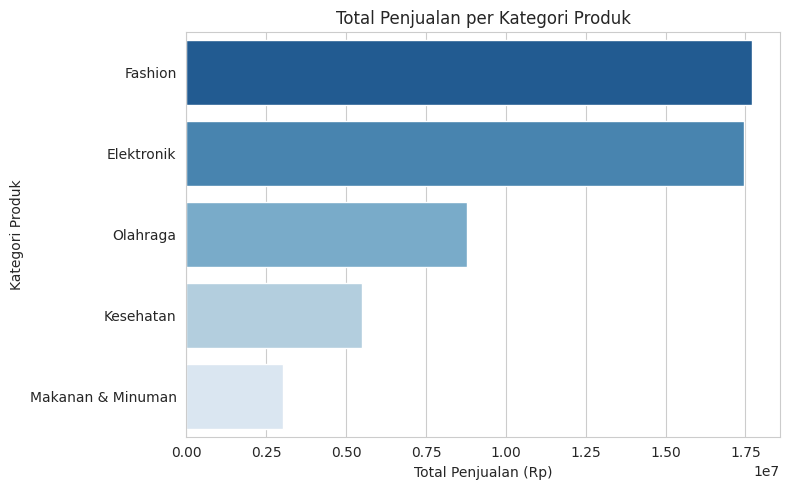

In [ ]:
total_kategori = df.groupby('kategori_produk')['total'].sum().sort_values(ascending=False)

plt.figure(figsize=(8,5))
sns.barplot(x=total_kategori.values, y=total_kategori.index,
            hue=total_kategori.index, palette='Blues_r', legend=False)
plt.title('Total Penjualan per Kategori Produk')
plt.xlabel('Total Penjualan (Rp)')
plt.ylabel('Kategori Produk')
plt.tight_layout()
plt.show()

In [ ]:
print("Penjualan tertinggi:", total_kategori.idxmax(), "-> Rp", f"{total_kategori.max():,.0f}")
print("Penjualan terendah :", total_kategori.idxmin(), "-> Rp", f"{total_kategori.min():,.0f}")

Penjualan tertinggi: Fashion -> Rp 17,695,000
Penjualan terendah : Makanan & Minuman -> Rp 3,029,000


### Jawaban Tugas Analisis 2
1. **Kategori penyumbang penjualan tertinggi dan terendah:**
   Tertinggi: **Fashion** (Rp17.695.000, ±34% dari total). Terendah: **Makanan & Minuman** (Rp3.029.000, ±6%).

2. **Rekomendasi bisnis untuk manajer Nusantara Mart:**
   - Jaga ketersediaan stok **Fashion dan Elektronik** karena keduanya menyumbang ±67% pendapatan.
   - Dorong **Makanan & Minuman** (penjualan terendah tetapi rating pelanggan tertinggi) lewat promo bundling/paket hemat agar nilai belanja naik.

---
## Latihan 3: Visualisasi Tren dengan Line Chart
**Tujuan:** melihat pola tren penjualan dari waktu ke waktu.

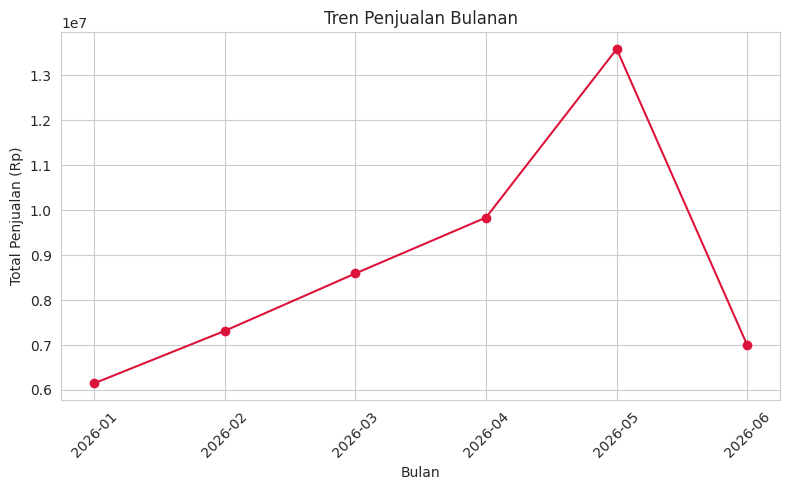

In [ ]:
df['tanggal'] = pd.to_datetime(df['tanggal'])
df['bulan'] = df['tanggal'].dt.to_period('M')
tren_bulanan = df.groupby('bulan')['total'].sum()

plt.figure(figsize=(8,5))
plt.plot(tren_bulanan.index.astype(str), tren_bulanan.values, marker='o', color='crimson')
plt.title('Tren Penjualan Bulanan')
plt.xlabel('Bulan')
plt.ylabel('Total Penjualan (Rp)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
print("Bulan penjualan tertinggi:", tren_bulanan.idxmax(), "-> Rp", f"{tren_bulanan.max():,.0f}")
print(tren_bulanan)

Bulan penjualan tertinggi: 2026-05 -> Rp 13,585,000
bulan
2026-01     6147000
2026-02     7314000
2026-03     8592000
2026-04     9837000
2026-05    13585000
2026-06     6992000
Freq: M, Name: total, dtype: int64


### Jawaban Tugas Analisis 3
1. **Bulan dengan penjualan tertinggi & kemungkinan penyebabnya:**
   **Mei 2026** (Rp13.585.000). Jumlah transaksi Mei (37) justru tidak terbanyak, tetapi nilai rata-rata per transaksinya tinggi (±Rp367 ribu). Kemungkinan penyebab: adanya **pesanan borongan/grosir** (mis. 25 earphone dan 40 botol minum) serta kenaikan penjualan Elektronik dan Olahraga. Kemungkinan promo perlu dicek lebih lanjut karena datanya tidak mencatat promo.

2. **Tren naik, turun, atau fluktuatif? Jelaskan:**
   **Naik dari Januari sampai Mei** (Rp6,1 juta → Rp13,6 juta), lalu **turun tajam di Juni** (±48% menjadi Rp7 juta). Jadi secara keseluruhan cenderung naik lalu turun, bukan naik terus-menerus.

---
## Latihan 4: Visualisasi Hubungan dengan Scatter Plot
**Tujuan:** melihat hubungan jumlah barang dengan total nilai pembelian.

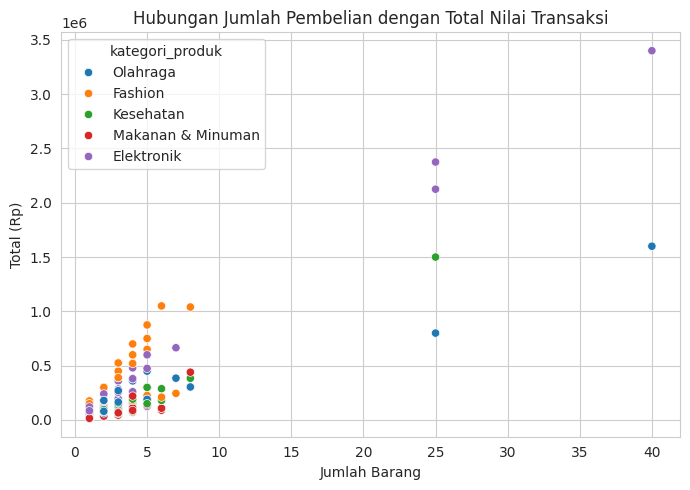

In [ ]:
plt.figure(figsize=(7,5))
sns.scatterplot(data=df, x='jumlah', y='total', hue='kategori_produk')
plt.title('Hubungan Jumlah Pembelian dengan Total Nilai Transaksi')
plt.xlabel('Jumlah Barang')
plt.ylabel('Total (Rp)')
plt.tight_layout()
plt.show()

In [ ]:
# Bantuan: koefisien korelasi (mendekati +1 = positif kuat, -1 = negatif kuat, 0 = tidak berhubungan)
print("Korelasi jumlah vs total:", round(df['jumlah'].corr(df['total']), 3))

Korelasi jumlah vs total: 0.854


### Jawaban Tugas Analisis 4
1. **Pola hubungan jumlah barang vs total transaksi:**
   **Hubungan positif dan kuat** (korelasi ≈ 0,85): semakin banyak barang dibeli, semakin besar total transaksi. Titik tidak sepenuhnya lurus karena total = jumlah × harga satuan, dan harga tiap produk berbeda.

2. **Titik data yang jauh dari pola umum (outlier) & kategorinya:**
   Titik di kanan atas, yaitu pembelian 25-40 barang: **Elektronik** (40 barang ≈ Rp3,4 juta; 25 barang ≈ Rp2,4 juta dan Rp2,1 juta), **Olahraga** (40 barang) dan **Kesehatan** (25 barang).

---
## Latihan 5: Distribusi & Deteksi Outlier (Histogram & Boxplot)
**Tujuan:** melihat sebaran rating pelanggan dan mendeteksi transaksi tidak wajar pada kolom `jumlah`.

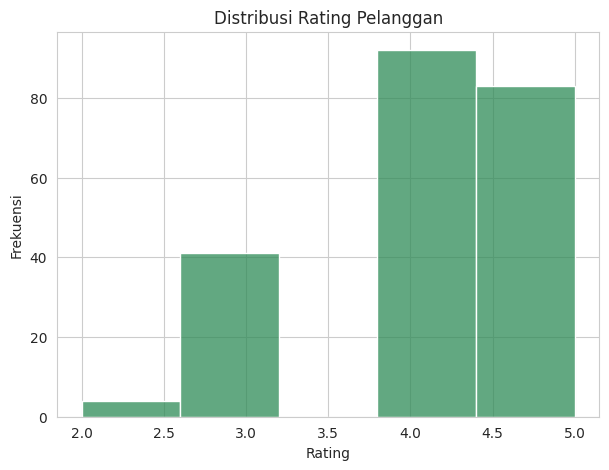

In [ ]:
# Histogram distribusi rating pelanggan
plt.figure(figsize=(7,5))
sns.histplot(df['rating_pelanggan'], bins=5, color='seagreen')
plt.title('Distribusi Rating Pelanggan')
plt.xlabel('Rating')
plt.ylabel('Frekuensi')
plt.show()

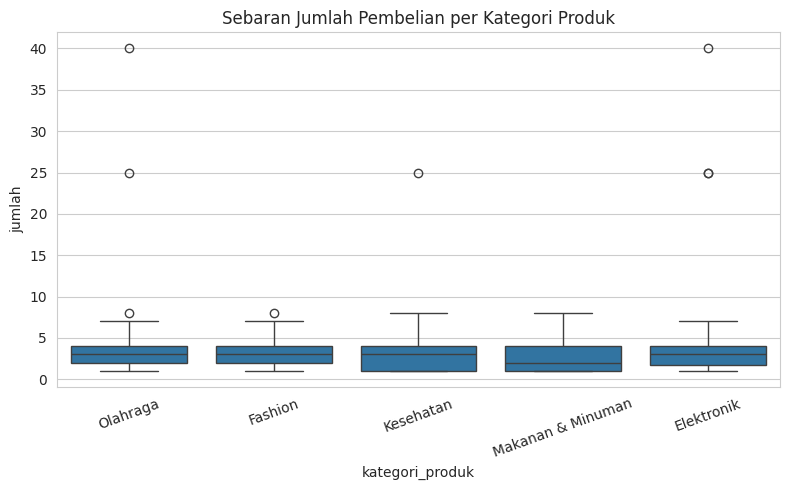

In [ ]:
# Boxplot jumlah pembelian per kategori (deteksi outlier)
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='kategori_produk', y='jumlah')
plt.title('Sebaran Jumlah Pembelian per Kategori Produk')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
# Bantuan: deteksi outlier dengan aturan IQR per kategori
Q1 = df.groupby('kategori_produk')['jumlah'].quantile(0.25)
Q3 = df.groupby('kategori_produk')['jumlah'].quantile(0.75)
IQR = Q3 - Q1
batas_bawah = Q1 - 1.5 * IQR
batas_atas  = Q3 + 1.5 * IQR

outlier = df[(df['jumlah'] < df['kategori_produk'].map(batas_bawah)) |
             (df['jumlah'] > df['kategori_produk'].map(batas_atas))]
print("Jumlah outlier:", len(outlier))
print(outlier.groupby('kategori_produk').size())
outlier.head(10)

Jumlah outlier: 8
kategori_produk
Elektronik    3
Fashion       1
Kesehatan     1
Olahraga      3
dtype: int64


,order_id,tanggal,kategori_produk,nama_produk,wilayah,jumlah,harga_satuan,total,metode_pembayaran,rating_pelanggan,bulan
39,1156,2026-02-05,Elektronik,Earphone Bluetooth,Surabaya,40,85000,3400000,E-Wallet,5,2026-02
76,1066,2026-03-14,Olahraga,Skipping Rope,Medan,25,32000,800000,COD,5,2026-03
79,1214,2026-03-14,Kesehatan,Termometer Digital,Medan,25,60000,1500000,E-Wallet,4,2026-03
111,1020,2026-04-06,Fashion,Tas Ransel,Jakarta,8,130000,1040000,COD,4,2026-04
121,1158,2026-04-17,Elektronik,Speaker Mini,Malang,25,95000,2375000,Transfer Bank,3,2026-04
148,1021,2026-05-06,Elektronik,Earphone Bluetooth,Malang,25,85000,2125000,E-Wallet,4,2026-05
151,1141,2026-05-08,Olahraga,Botol Minum 1L,Denpasar,40,40000,1600000,COD,5,2026-05
158,1024,2026-05-16,Olahraga,Sarung Tangan Gym,Medan,8,38000,304000,COD,4,2026-05


### Jawaban Tugas Analisis 5
1. **Bentuk distribusi rating pelanggan:**
   **Cenderung tinggi** (condong ke kiri). Rating 4 muncul 92 kali dan rating 5 muncul 83 kali, sehingga ±80% pelanggan memberi nilai 4-5. Rating 3 ada 41, rating 2 hanya 4, dan tidak ada rating 1.

2. **Kategori yang memiliki outlier di boxplot & kemungkinan penyebabnya:**
   **Elektronik** (3 titik), **Olahraga** (3 titik), **Kesehatan** (1 titik), dan **Fashion** (1 titik). Totalnya 8 outlier berdasarkan aturan IQR. Kemungkinan penyebab: **pembelian grosir oleh reseller/instansi** (mis. 25-40 earphone atau botol minum sekaligus). Rating transaksi ini umumnya baik (3-5), jadi bukan transaksi bermasalah.

---
## Latihan 6: Dashboard Sederhana dengan Subplot
**Tujuan:** menggabungkan beberapa visualisasi dalam satu tampilan.

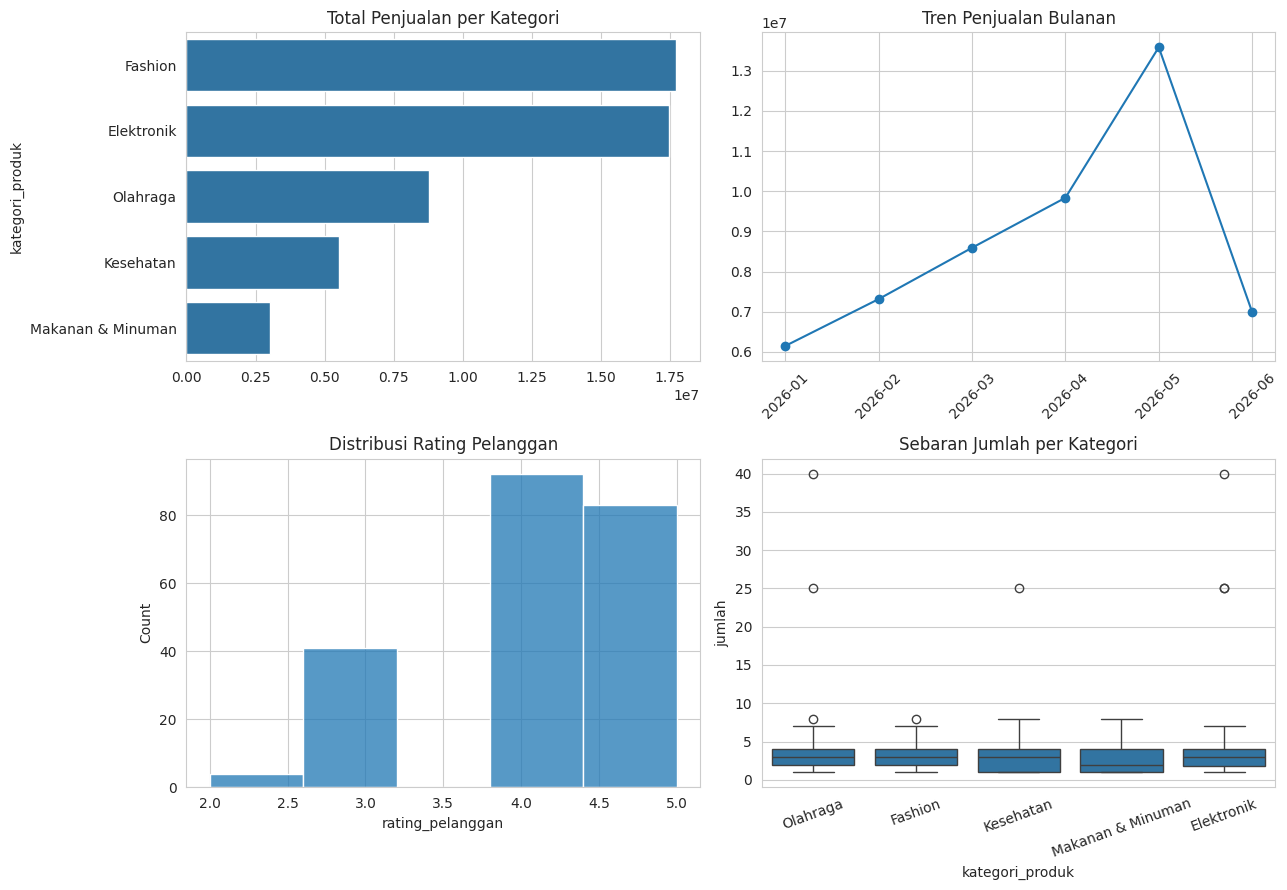

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13,9))

sns.barplot(x=total_kategori.values, y=total_kategori.index, ax=axes[0,0])
axes[0,0].set_title('Total Penjualan per Kategori')

axes[0,1].plot(tren_bulanan.index.astype(str), tren_bulanan.values, marker='o')
axes[0,1].set_title('Tren Penjualan Bulanan')
axes[0,1].tick_params(axis='x', rotation=45)

sns.histplot(df['rating_pelanggan'], bins=5, ax=axes[1,0])
axes[1,0].set_title('Distribusi Rating Pelanggan')

sns.boxplot(data=df, x='kategori_produk', y='jumlah', ax=axes[1,1])
axes[1,1].set_title('Sebaran Jumlah per Kategori')
axes[1,1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

### Jawaban Tugas Analisis 6
1. **Keuntungan dashboard dibanding grafik terpisah:**
   Beberapa aspek (kategori, tren, rating, outlier) bisa dilihat dan dibandingkan sekaligus dalam satu tampilan, sehingga hubungan antartemuan lebih mudah terlihat (misalnya lonjakan Mei cocok dengan outlier di boxplot), lebih ringkas, dan lebih mudah dipresentasikan kepada manajer.

2. **Keputusan bisnis sebagai manajer:**
   - Prioritaskan stok Fashion dan Elektronik.
   - Siapkan skema harga grosir untuk pembeli borongan.
   - Selidiki penyebab turunnya penjualan Juni.
   - Naikkan penjualan Makanan & Minuman lewat bundling.

---
## Kesimpulan
Dari Latihan 1-6 dipelajari cara memuat dan meringkas data dengan Pandas, memilih jenis grafik yang tepat (bar, line, scatter, histogram, boxplot), mendeteksi outlier dengan aturan IQR, dan menggabungkan grafik dalam dashboard. Temuan utama data Nusantara Mart: Fashion dan Elektronik menyumbang ±67% penjualan, penjualan memuncak pada Mei 2026 lalu turun di Juni, dan lonjakan tersebut banyak dipengaruhi pesanan borongan (outlier). Rata-rata transaksi (mean) jauh di atas median sehingga median lebih mewakili transaksi biasa. Rekomendasinya: jaga stok kategori utama, siapkan skema harga grosir, dan dorong penjualan Makanan & Minuman.

---
